##Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [2]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-optimize]


In [3]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



###Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

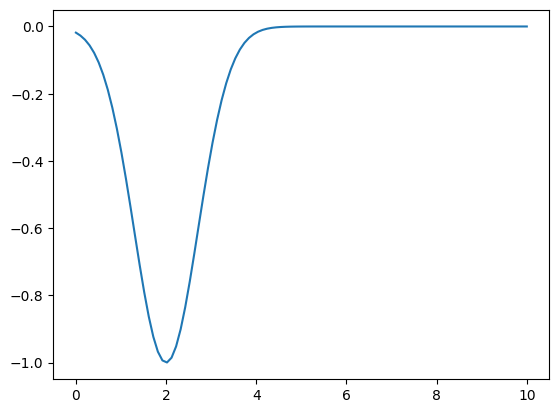

2.0202020202020203


In [4]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

###Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [5]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [6]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.988484547652788e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.786e-06  8.505e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [7]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.999999999999997
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[1.99999994 0.99999995]


In [8]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000009 1.00000005]


/tmp/ipykernel_12899/2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



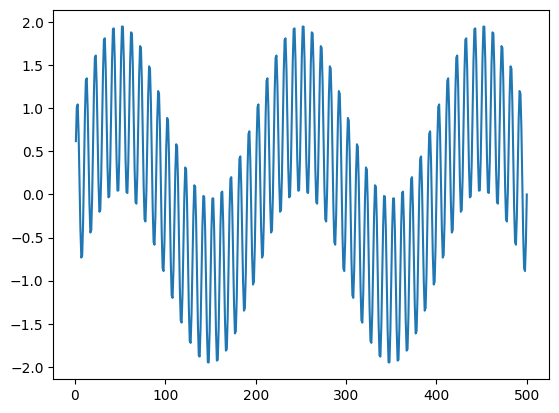

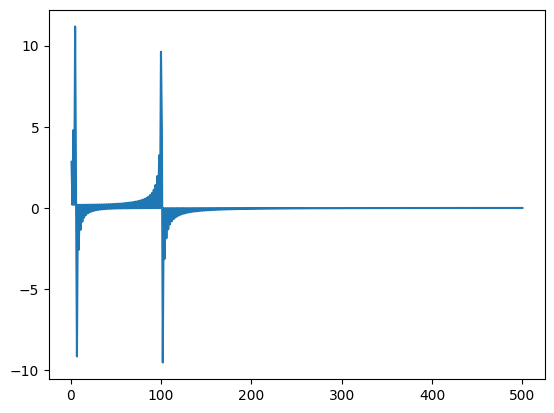

([<matplotlib.lines.Line2D at 0x7de67bce51d0>], None)

In [9]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

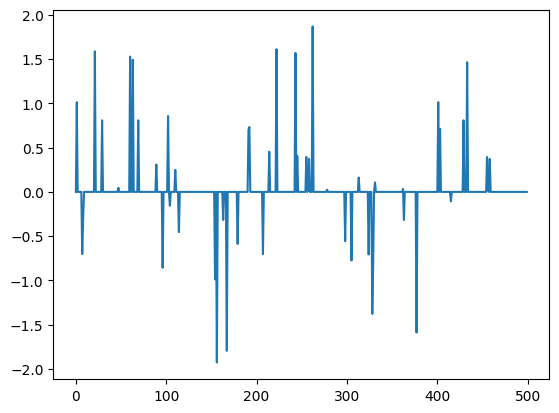

([<matplotlib.lines.Line2D at 0x7de67bd46850>], None)

In [10]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


         Current function value: 0.000000
         Iterations: 3
         Function evaluations: 38589
         Gradient evaluations: 77


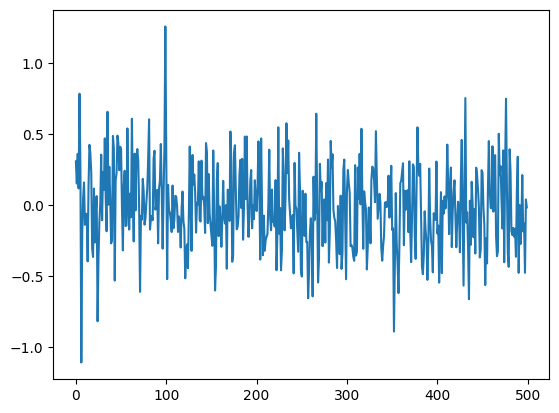

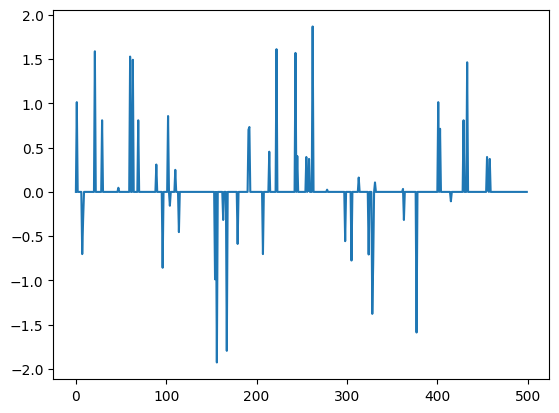

([<matplotlib.lines.Line2D at 0x7de678393b10>], None)

In [11]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 1.367900497097765e-05
            Iterations: 100
            Function evaluations: 51345
            Gradient evaluations: 101


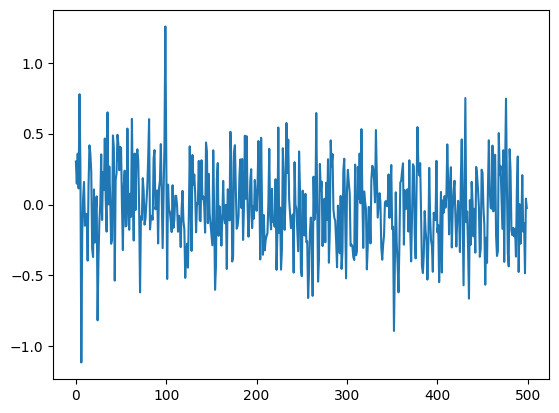

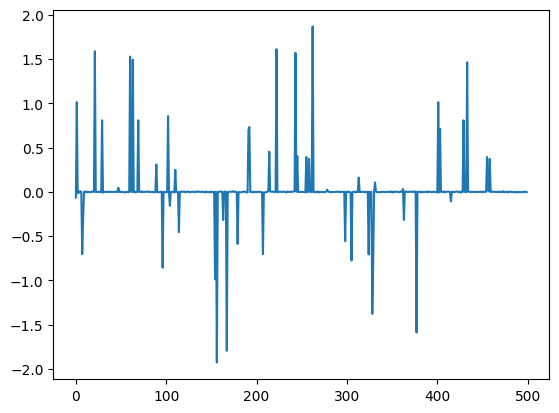

([<matplotlib.lines.Line2D at 0x7de678259f90>], None)

In [12]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [13]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 51.036790252463774
            Iterations: 100
            Function evaluations: 50912
            Gradient evaluations: 101


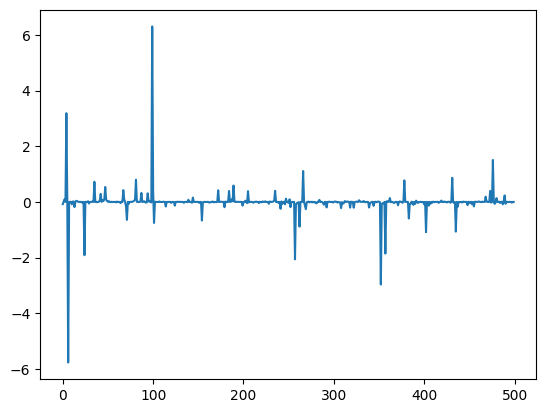

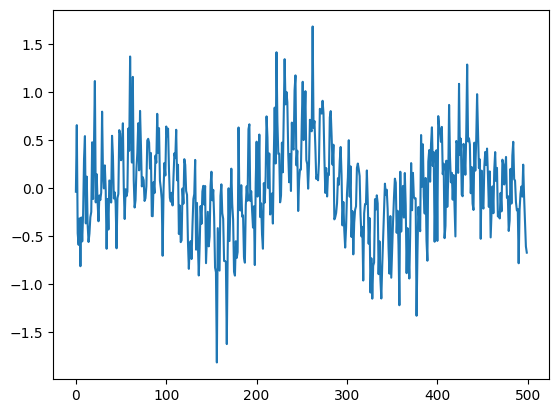

([<matplotlib.lines.Line2D at 0x7de67832f9d0>], None)

In [14]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

# My observations

*The code shows that a signal can be reconstructed from far fewer samples than normally required, provided that it is sparse in some representation. Here the signal consists of only a few frequencies, so it can be recovered from a small number of randomly chosen samples by finding the simplest (sparsest) combination of frequencies consistent with the measurements.

* This idea is useful in EO in several ways. Satellites have limited storage and downlink capacity, so acquiring fewer measurements on board and reconstructing the full image on the ground can reduce the amount of transmitted data. In radar imaging, compressive sensing allows images to be formed from fewer pulses, and in SAR tomography it is used to reconstruct the 3D structure of buildings and forests from a limited number of acquisitions. In hyperspectral imaging, which produces hundreds of bands, coded-aperture systems can capture the data with fewer measurements. Compressive sensing also enables simple single-pixel cameras, which are attractive for small satellites such as CubeSats. Finally, the same reconstruction principle can be used to fill gaps in images, for example pixels covered by clouds or missing stripes, such as those in Landsat 7 images after its scan line corrector failed.


## Exercise 1

In [15]:
import rasterio
from pathlib import Path

In [16]:
from google.colab import drive
drive.mount('/content/drive')

!pip install rasterio -q

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from scipy.stats import skew

Mounted at /content/drive


In [17]:
DATA = Path("/content/drive/MyDrive/ml_lab2_data")   # adjust if 'data' is inside another folder on your Drive

REGIONS = {"Natural": "natural", "Urban": "urban"}
S2_BANDS = ["B02", "B03", "B04", "B08"]
S1_BANDS = ["VV", "VH"]

s2_files = {
    region: {b: DATA / folder / f"sentinel2_{b.lower()}.tiff" for b in S2_BANDS}
    for region, folder in REGIONS.items()
}
s1_files = {
    region: {b: DATA / folder / f"sentinel1_{b.lower()}.tiff" for b in S1_BANDS}
    for region, folder in REGIONS.items()
}

data loading

In [30]:
def load_band(path):
    with rasterio.open(path) as src:
        band = src.read(1).astype(float)
        nodata = src.nodata
    if nodata is not None:
        band[band == nodata] = np.nan
    #band[band == 0] = np.nan
    band[~np.isfinite(band)] = np.nan
    return band

s2 = {region: {b: load_band(p) for b, p in bands.items()} for region, bands in s2_files.items()}
s1 = {region: {b: load_band(p) for b, p in bands.items()} for region, bands in s1_files.items()}

for name, data in [("S2", s2), ("S1", s1)]:
    for region in data:
        for b, arr in data[region].items():
            print(f"{name} {region:8} {b}: shape {arr.shape}, "
                  f"min {np.nanmin(arr):.4f}, max {np.nanmax(arr):.4f}, "
                  f"no-data {np.isnan(arr).mean()*100:.1f}%")

S2 Natural  B02: shape (864, 925), min 0.0000, max 65535.0000, no-data 0.0%
S2 Natural  B03: shape (864, 925), min 0.0000, max 38882.0000, no-data 0.0%
S2 Natural  B04: shape (864, 925), min 0.0000, max 40782.0000, no-data 0.0%
S2 Natural  B08: shape (864, 925), min 0.0000, max 65535.0000, no-data 0.0%
S2 Urban    B02: shape (1032, 1292), min 0.0000, max 65535.0000, no-data 0.0%
S2 Urban    B03: shape (1032, 1292), min 0.0000, max 65535.0000, no-data 0.0%
S2 Urban    B04: shape (1032, 1292), min 0.0000, max 65535.0000, no-data 0.0%
S2 Urban    B08: shape (1032, 1292), min 0.0000, max 65535.0000, no-data 0.0%
S1 Natural  VV: shape (2334, 2500), min 0.0000, max 65535.0000, no-data 0.0%
S1 Natural  VH: shape (2334, 2500), min 0.0000, max 65535.0000, no-data 0.0%
S1 Urban    VV: shape (1997, 2500), min 0.0000, max 65535.0000, no-data 0.0%
S1 Urban    VH: shape (1997, 2500), min 0.0000, max 65535.0000, no-data 0.0%


helper functions

In [36]:
def valid(arr):
    """Returns only valid (non-NaN) pixel values as a 1D array."""
    return arr[np.isfinite(arr)]

def stretch(arr):
    """Contrast stretch for display only (2nd–98th percentile)."""
    lo, hi = np.nanpercentile(arr, [2, 98])
    return np.clip((arr - lo) / (hi - lo), 0, 1)

def show_bands(data, bands):
    """Grid of images: rows = regions, columns = bands."""
    regions = list(data)
    fig, axes = plt.subplots(len(regions), len(bands),
                             figsize=(4 * len(bands), 4 * len(regions)), squeeze=False)
    for row, region in enumerate(regions):
        for col, b in enumerate(bands):
            axes[row, col].imshow(stretch(data[region][b]), cmap='gray')
            axes[row, col].set_title(f"{region} – {b}")
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()

def compare_histograms(data, bands, bins=100, xlabel="Pixel value"):
    """For each band, plots the normalized histograms (PDF) of all regions on one plot."""
    fig, axes = plt.subplots(1, len(bands), figsize=(5 * len(bands), 4), squeeze=False)
    for ax, b in zip(axes[0], bands):
        all_values = np.concatenate([valid(data[r][b]) for r in data])
        lo, hi = np.percentile(all_values, [0.5, 99.5])
        edges = np.linspace(lo, hi, bins + 1) #equal bins
        for region in data:
            ax.hist(valid(data[region][b]), bins=edges, density=True, alpha=0.5, label=region)
        ax.set_title(b)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Probability density")
        ax.legend()
    plt.tight_layout()
    plt.show()

def print_stats(data, bands):
    """Table with basic statistics of each band in each region."""
    print(f"{'Region':<9}{'Band':<10}{'mean':>10}{'median':>10}{'std':>10}{'skewness':>10}")
    for region in data:
        for b in bands:
            v = valid(data[region][b])
            print(f"{region:<9}{b:<10}{v.mean():>10.4f}{np.median(v):>10.4f}"
                  f"{v.std():>10.4f}{skew(v):>10.2f}")

# Sentinel-2

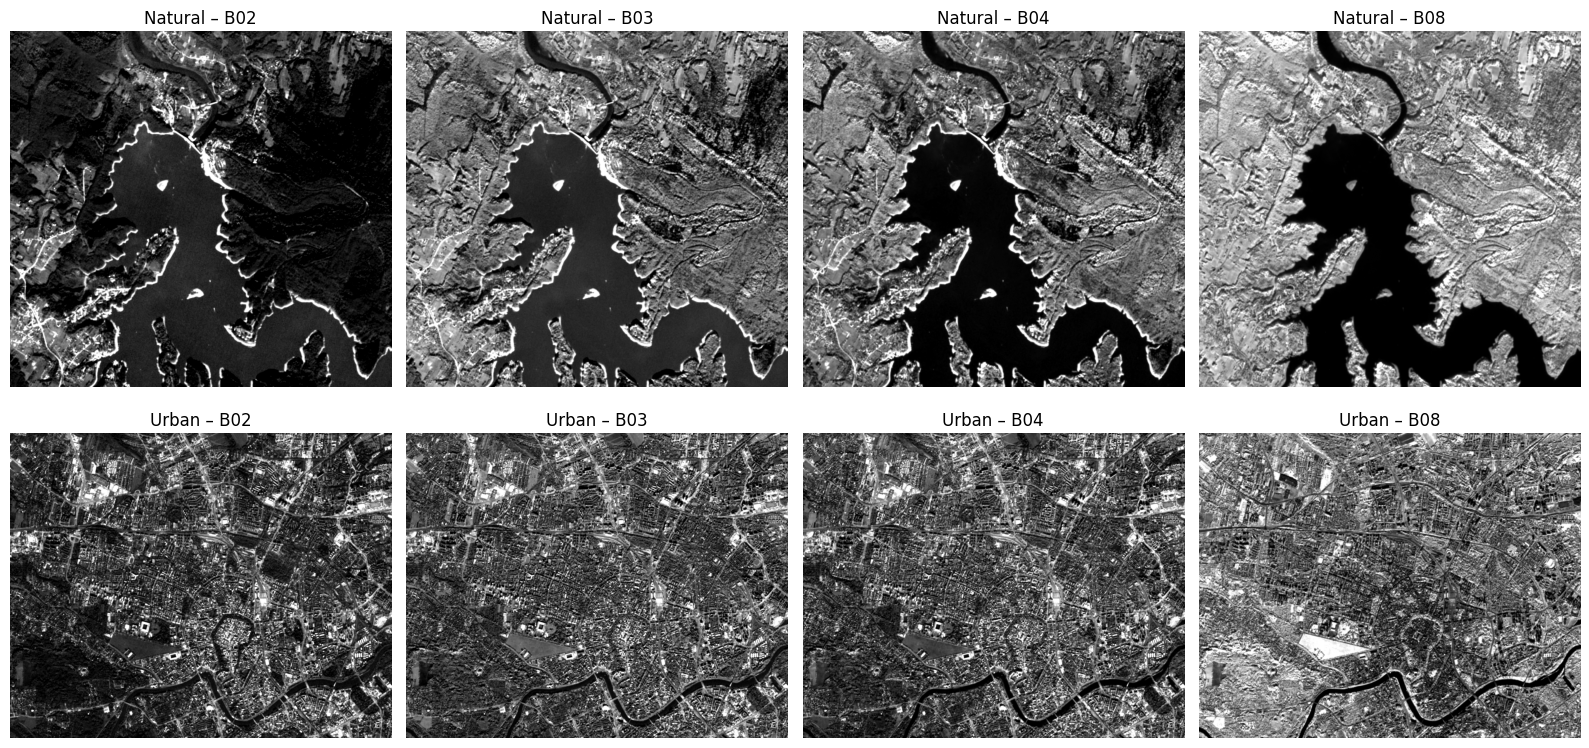

In [31]:
show_bands(s2, S2_BANDS)

Exercise 1.2

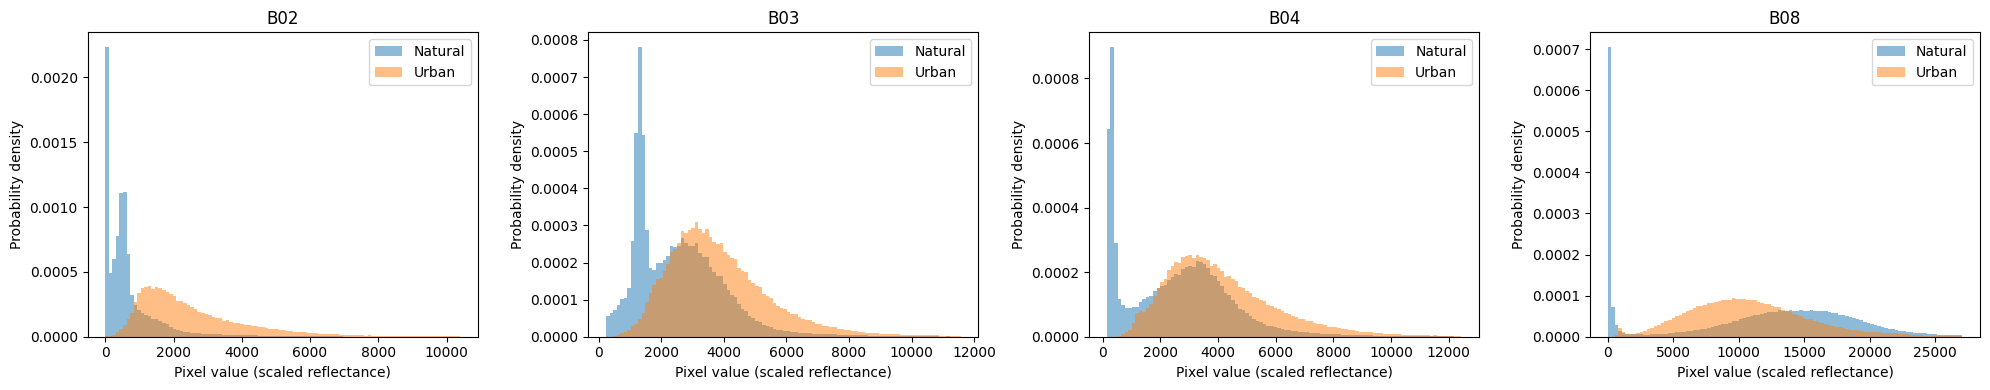

In [37]:
compare_histograms(s2, S2_BANDS, xlabel="Pixel value (scaled reflectance)")

In [23]:
print_stats(s2, S2_BANDS)

Region   Band            mean    median       std  skewness
Natural  B02         888.4289  564.0000 1037.0986      5.64
Natural  B03        2550.3181 2353.0000 1476.5433      1.73
Natural  B04        2597.0943 2602.0000 1947.5669      1.06
Natural  B08       12581.277213559.0000 6879.3978     -0.25
Urban    B02        2640.2799 2104.0000 1966.6477      3.65
Urban    B03        3950.6894 3591.0000 1976.7347      3.38
Urban    B04        4210.8231 3768.0000 2240.6708      2.71
Urban    B08       10787.259910407.0000 4589.6940      0.61


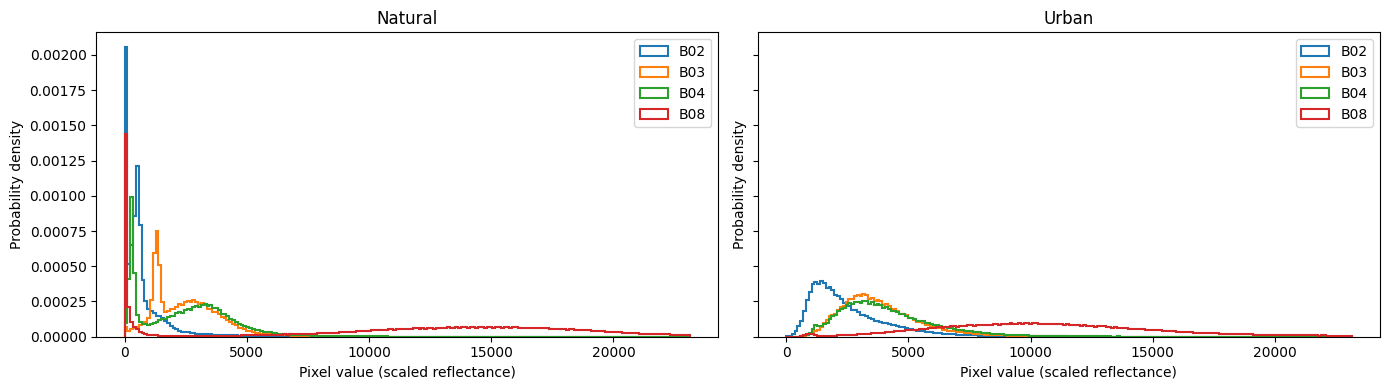

In [38]:
all_values = np.concatenate([valid(s2[r][b]) for r in s2 for b in S2_BANDS])
lo, hi = np.percentile(all_values, [0.5, 99.5])
edges = np.linspace(lo, hi, 201)

fig, axes = plt.subplots(1, len(s2), figsize=(7 * len(s2), 4), sharey=True, squeeze=False)
for ax, region in zip(axes[0], s2):
    for b in S2_BANDS:
        ax.hist(valid(s2[region][b]), bins=edges, density=True,
                histtype='step', linewidth=1.5, label=b)
    ax.set_title(region)
    ax.set_xlabel("Pixel value (scaled reflectance)")
    ax.set_ylabel("Probability density")
    ax.legend()
plt.tight_layout()
plt.show()

## Observations from Sentinel-2 part
* The most important difference between the two regions is the shape of the
histograms. The histograms of the natural area are bimodal, while the urban histograms are unimodal. The natural area consists of two very different surfaces, water and land, and each of them forms its own peak. In B03 the narrow, high peak at about 1300 corresponds to water, which reflects some green light, and the broad hump at about 2800 to land. In B04 the water peak lies close to zero, as water absorbs red light, and the land hump is at about 3300. The separation is the strongest in B08, where water is almost black and forms a peak at zero, while vegetation, which strongly reflects near-infrared light, forms a very broad hump between 5000 and 25000. B08 is therefore the band that best separates water from land. In B02 there is only one main peak at low values, because both water and vegetation are dark in blue light, followed by a long tail towards high values caused by fields, roads and buildings.

* The urban area is brighter in the visible bands. Its mean value in B02 is 2640, compared to 888 in the natural area, which is three times more, because concrete, roofs and asphalt reflect visible light more strongly than water and vegetation. In B03 and B04 the difference is smaller, as the land hump of the natural area overlaps with the urban histogram. In B08 the situation is reversed: the vegetation hump of the natural area lies higher than the urban histogram, whose median is 10407. There is no visible water peak in the urban histograms, since the river covers only a small fraction of the image. The strong overlap of the natural land and urban histograms in B03 and B04 shows that these areas could not be separated using a single visible band. This explains why classification methods in machine learning use several bands at once or their combinations, such as spectral indices.

* The statistics confirm that none of the histograms resembles a Gaussian distribution. Almost all of them are right-skewed, with long tails towards high values. The asymmetry and bimodality show that the histogram of a satellite image is in fact a mixture of the distributions of different land cover types, which is the basis of many classification methods, such as Gaussian mixture models. The standard deviation requires careful interpretation. In the visible bands the urban area has a higher standard deviation, which reflects its heterogeneity. In B08, the natural area has a higher standard deviation, because it contains two very distant groups of pixels: water (close to zero) and vegetation (high values). A high standard deviation can indicate either many different surfaces or two very different ones.

* In the natural area, B08 is clearly separated from the visible bands, which is the typical signature of vegetation: low reflectance in visible light and high reflectance in the near-infrared. In the urban area the bands lie closer to each other, and B03 and B04 almost overlap, because grey surfaces such as concrete and asphalt reflect all visible wavelengths similarly. The near-infrared band is still higher thanks to urban greenery, but the gap is much smaller.

# Sentinel-1

In [25]:
#decibels
for region in s1:
    for pol in S1_BANDS:
        lin = s1[region][pol]
        if np.nanmin(lin) < 0:
            print(f"Warning: {region} {pol} has negative values – it may already be in dB!")
        with np.errstate(divide='ignore', invalid='ignore'):
            s1[region][f"{pol}_dB"] = 10 * np.log10(lin)
    s1[region]["VV-VH_dB"] = s1[region]["VV_dB"] - s1[region]["VH_dB"]   # = VV/VH ratio in dB

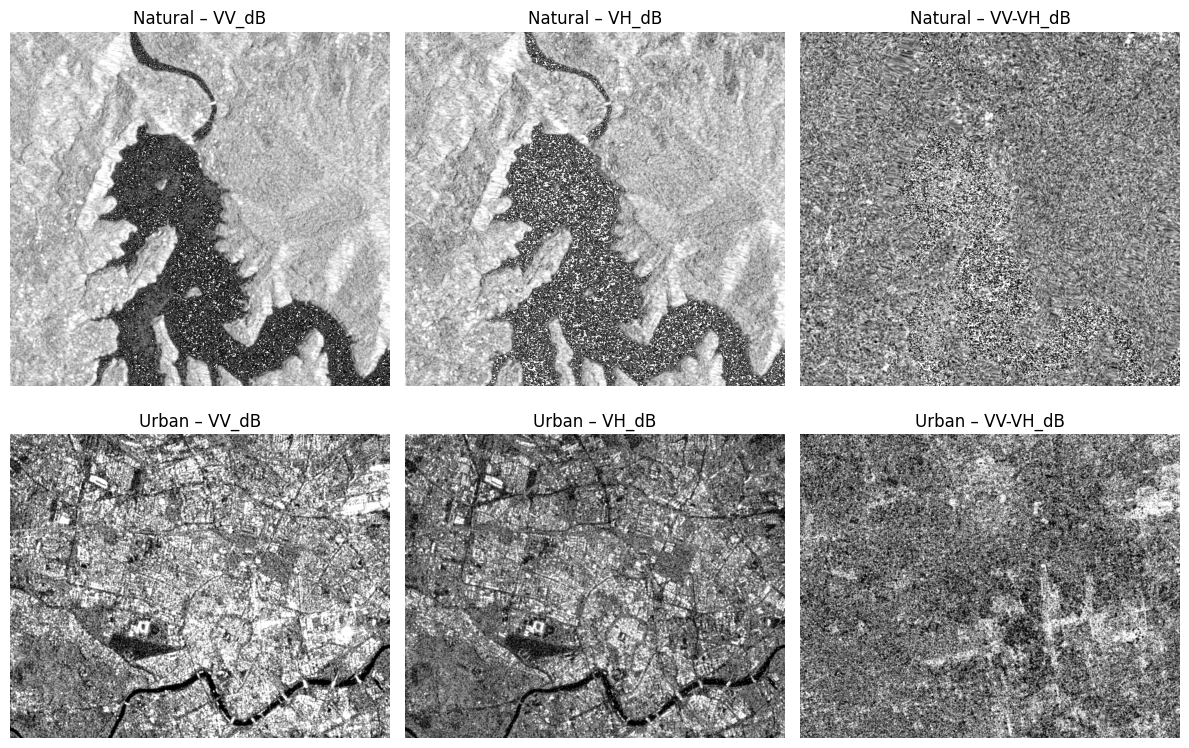

In [26]:
show_bands(s1, ["VV_dB", "VH_dB", "VV-VH_dB"])

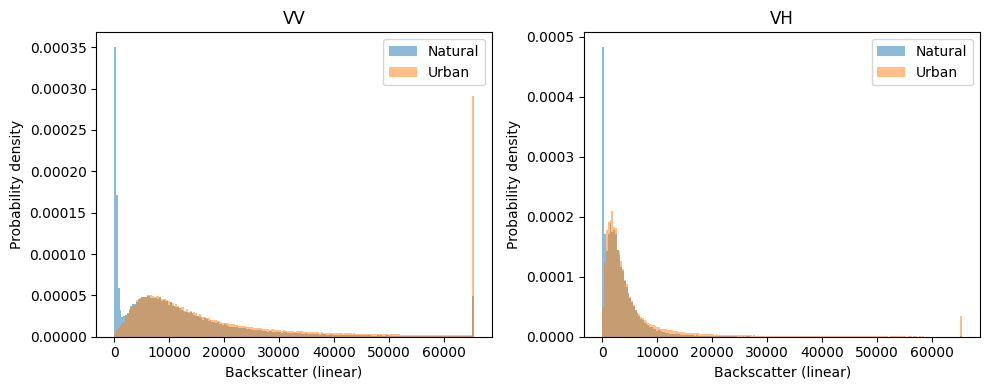

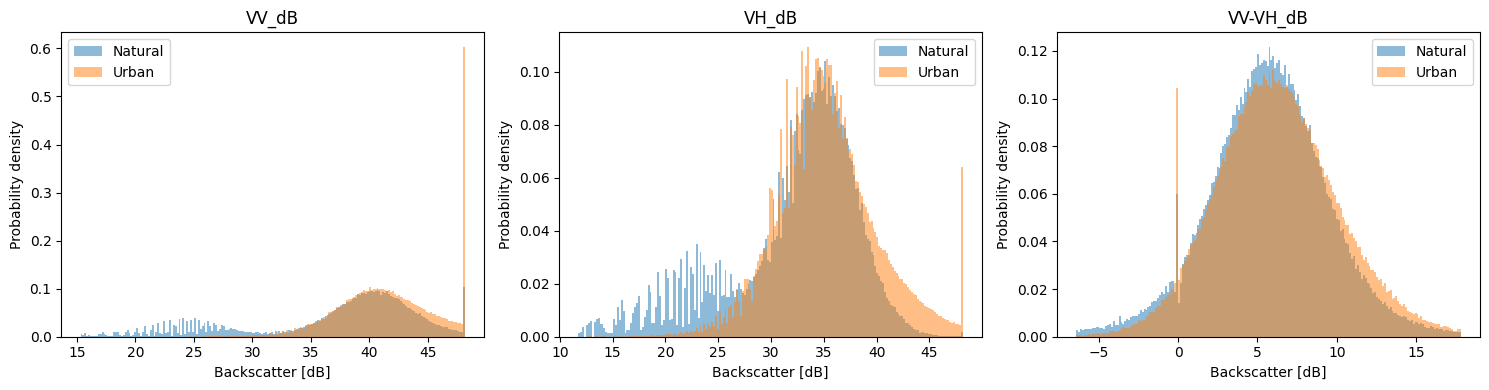

In [27]:
compare_histograms(s1, S1_BANDS, xlabel="Backscatter (linear)")
compare_histograms(s1, ["VV_dB", "VH_dB", "VV-VH_dB"], xlabel="Backscatter [dB]")

In [28]:
print_stats(s1, ["VV_dB", "VH_dB", "VV-VH_dB"])

Region   Band            mean    median       std  skewness
Natural  VV_dB        36.9972   39.2973    7.6484     -1.17
Natural  VH_dB        31.9544   33.6361    6.5660     -1.18
Natural  VV-VH_dB      5.6335    5.7029    4.1644     -0.29
Urban    VV_dB        41.4091   41.2685    4.1624     -0.25
Urban    VH_dB        35.1979   34.9290    4.6843      0.19
Urban    VV-VH_dB      6.2129    6.0637    3.9107      0.26


## Observations from Sentinel-1 part
* As with Sentinel-2, the values are not physical quantities. The data were exported from the Copernicus Browser as 16-bit integers, so the linear values range from 0 to 65535, and all brighter pixels were clipped to the maximum value. This is visible as a high peak at the right end of the linear histograms and at 48,2 dB in the decibel histograms, which corresponds to 10*log10(65535). The decibel values should therefore be treated as relative: they are shifted compared to the typical physical backscatter values, which for Sentinel-1 are usually negative. This shift does not affect the shape of the histograms or the comparison between regions.

* The data were converted to decibels. In the linear scale, almost all pixels are compressed near zero with a long tail to the right, while the logarithmic scale makes the histograms readable. Secondly, the speckle noise of radar images is multiplicative. The logarithm turns multiplication into addition, which makes the distributions more symmetric.

* Some features of the histograms are artifacts rather than properties of the terrain. The comb-like pattern at low values in the natural area histograms results from integer pixel values: at low values, neighboring integers differ  in decibels, so some bins remain empty. This mostly concerns water, which has the lowest values. The narrow peak at exactly 0 dB in the urban VV−VH histogram consists of pixels in which both VV and VH were clipped, so their ratio equals one. The negative values of VV−VH are not an error: they mean that in a given pixel VH was stronger than VV, which happens mostly over water, where both signals are close to the noise level.

* As in Sentinel-2, the natural area histograms are bimodal. Water forms a separate group at low values (about 20–30 dB in VV), because its smooth surface reflects the radar wave away from the satellite like a mirror, so the reservoir appears dark in the images. Land forms the main hump at about 40 dB in VV and 34 dB in VH. The left tail formed by water results in a clearly negative skewness (−1,17 and −1,18) and a high standard deviation (7,65 dB in VV). The urban histograms are unimodal, shifted slightly to the right and have a long right tail ending in the ending peak. This is caused by double-bounce scattering.

* Surprisingly, the land humps of both regions almost overlap in VV. The urban median (41,3 dB) is only slightly higher than the natural one (39,3 dB), even though the latter is lowered by water. There are several possible reasons. The city also contains smooth surfaces, such as roads, parking lots and flat roofs, which appear dark to the radar, as can be seen in the VH image, where streets form dark lines. The natural area is mountainous, and slopes facing the satellite appear very bright, which raises the backscatter of the natural area. Finally, forest canopies scatter the wave in many directions, which also produces a relatively strong signal. The difference between the regions lies in the tail and the saturation rather than in the center of the distribution. In VH the city is slightly brighter and has a longer right tail.

* The VV−VH ratio histograms of both regions are almost identical and close to a Gaussian distribution, with means of 5,6 dB in the natural area and 6,2 dB in the city. The city has a slightly higher ratio, because double-bounce scattering preserves polarization, so VV increases more than VH. This difference is too small for the ratio to separate the two regions. Water does not form a separate hump in the ratio, but a left tail with negative values, since both signals over water are close to the noise level and their ratio is random. This is visible in the ratio image, where the reservoir appears grainy. Speckle is clearly visible in all images, especially as white dots over water in VH, and the ratio image of the natural area looks almost like noise, as dividing two noisy images amplifies the noise even more.

## Sentinel-1 and Sentinel-2 comparison
* The two sensors measure different properties of the surface. Sentinel-2 is a passive optical sensor while Sentinel-1 is an active radar that sends its own microwave signal and measures how much of it returns, so its values depend on the structure, roughness and geometry of the surface. This difference is clearly reflected in the histograms.

* Both sensors separate water from land very well. In both cases the natural area histograms are bimodal, with water forming a distinct group at low values: in Sentinel-2 because water absorbs near-infrared light, and in Sentinel-1 because its smooth surface reflects the radar wave away from the satellite.

* The natural area and the city are much better separated by Sentinel-2. The city is clearly brighter in the visible bands, while vegetation is brighter in the near-infrared, and plotting all bands together reveals distinct spectral signatures of both areas. In Sentinel-1 the land humps of both regions largely overlap, and the difference is visible mainly in the right tail and the saturation peak caused by buildings. This is partly due to the mountainous terrain (Solina Lake in Sanocko-Turczańskie Mountains) of the natural area: in radar images, topography strongly influences the signal, as slopes facing the satellite appear bright regardless of land cover, while optical data are much less affected by it.

* The histograms of both sensors are non-Gaussian and represent mixtures of the distributions of different land cover types. In both cases, combining bands provides more information than single bands: in Sentinel-2 the near-infrared band adds information not visible in the visible bands, while in Sentinel-1 the VV−VH ratio turned out to separate the regions poorly.



# Steganography
Loading the Sentinel-2 4th band

In [39]:
IMG_REGION, IMG_BAND = "Natural", "B04"

with rasterio.open(s2_files[IMG_REGION][IMG_BAND]) as src:
    original = src.read(1)

print("Data type:", original.dtype)
print("Min / max:", original.min(), original.max())
print("Unique values:", np.unique(original).size,
      "out of", int(original.max()) - int(original.min()) + 1, "possible in this range")

Data type: uint16
Min / max: 0 40782
Unique values: 2327 out of 40783 possible in this range


The B04 band of the natural area was loaded again in its original integer type (uint16). Only 2327 of the 40783 possible values in the data range actually occur in the image. This confirms that the Copernicus Browser rescaled the original Sentinel-2 values from the 0–10000 range to the 0–65535 range, so only about every 6,5th value is used and there are regular gaps between them.

Next, I'm clearing the 2 Least significant Bits and inserting random values to that place. 2 LSB can make difference of maximum 3 units, so I expect no significant change in the imagery.

In [41]:
rng = np.random.default_rng(seed=42)
random_bits = rng.integers(0, 4, size=original.shape, dtype=original.dtype)

mask = original.dtype.type(3)
manipulated = (original & ~mask) | random_bits # clearing 2 LSBs, inserting random ones

diff = manipulated.astype(int) - original.astype(int)
print("Possible differences:", np.unique(diff))
print(f"Changed pixels: {(diff != 0).mean()*100:.1f}%")
print(f"Max change relative to data range: {np.abs(diff).max() / original.max() * 100:.4f}%")

Possible differences: [-3 -2 -1  0  1  2  3]
Changed pixels: 75.0%
Max change relative to data range: 0.0074%


The two least significant bits of every pixel were replaced with random values from 0 to 3. As a result, pixel values changed by at most |3|, and 75% of the pixels were modified, which matches the theoretical expectation: the random bits are identical to the original ones with a probability of 1/4. The maximum change corresponds to only 0,0074% of the data range.

Visualizing the before and after of steganography:

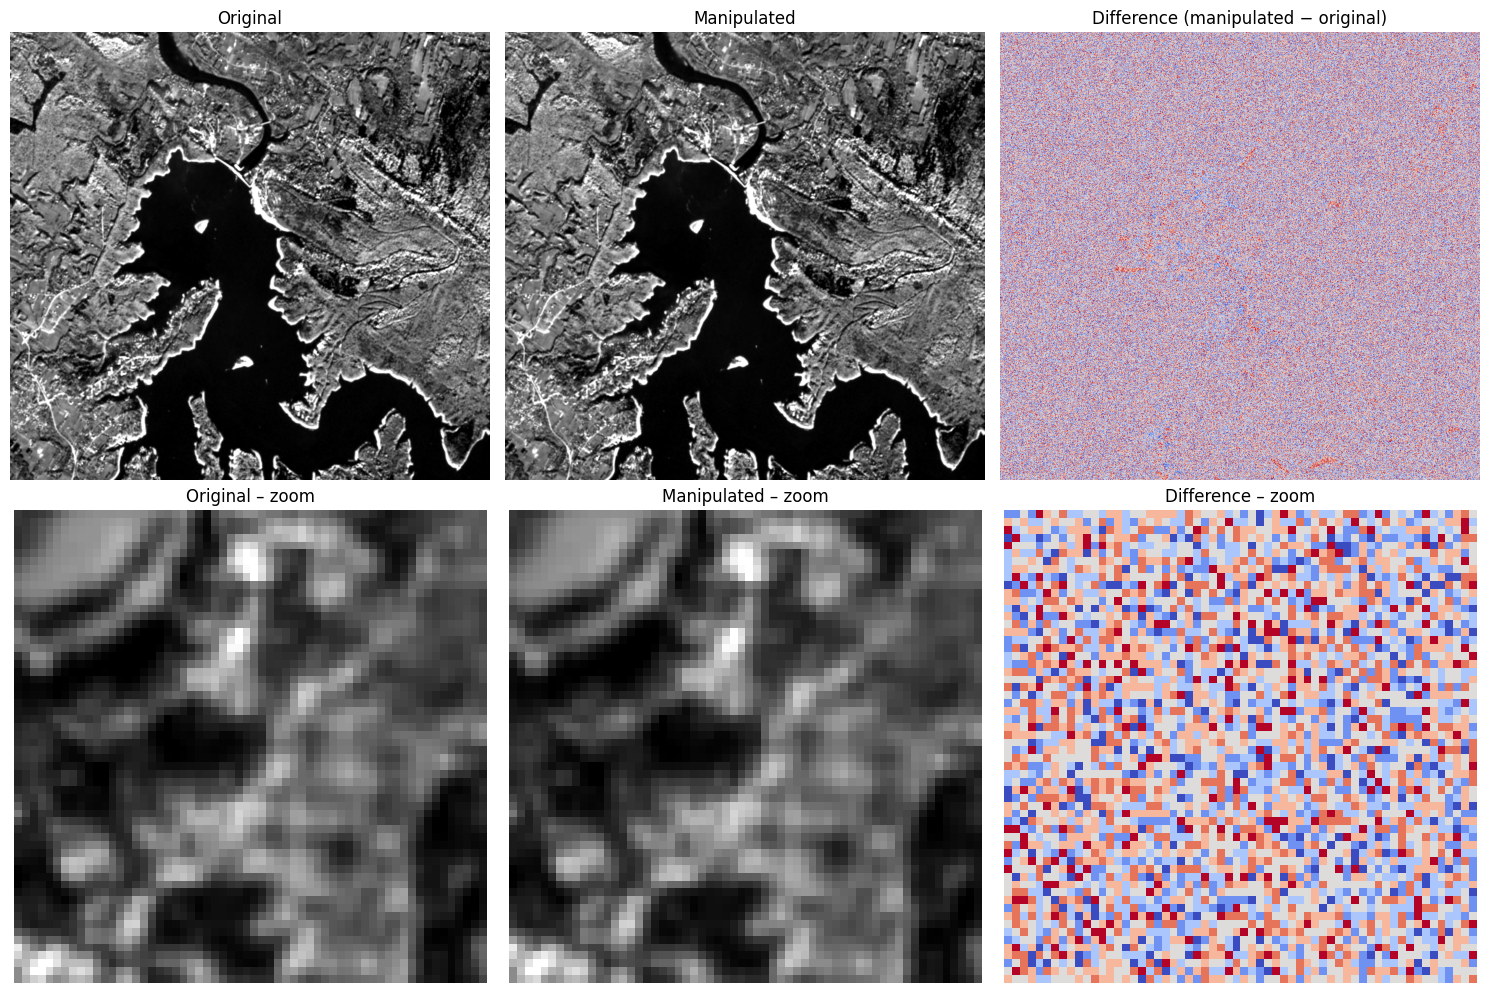

MSE: 2.52   PSNR: 88.2 dB


In [42]:
lo, hi = np.percentile(original, [2, 98])
show = lambda a: np.clip((a.astype(float) - lo) / (hi - lo), 0, 1)

r0, c0, size = 200, 200, 60 # zooming in to see pixels more clearly
crop = lambda a: a[r0:r0 + size, c0:c0 + size]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for col, (img, title) in enumerate([(original, "Original"), (manipulated, "Manipulated")]):
    axes[0, col].imshow(show(img), cmap='gray')
    axes[0, col].set_title(title)
    axes[1, col].imshow(show(crop(img)), cmap='gray', interpolation='nearest')
    axes[1, col].set_title(f"{title} – zoom")

axes[0, 2].imshow(diff, cmap='coolwarm', vmin=-3, vmax=3)
axes[0, 2].set_title("Difference (manipulated − original)")
axes[1, 2].imshow(crop(diff), cmap='coolwarm', vmin=-3, vmax=3, interpolation='nearest')
axes[1, 2].set_title("Difference – zoom")

for a in axes.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

mse = np.mean(diff.astype(float) ** 2)
psnr = 10 * np.log10(float(original.max()) ** 2 / mse)
print(f"MSE: {mse:.2f}   PSNR: {psnr:.1f} dB")

The manipulation has no visible effect on image quality, neither in the whole image nor in the zoomed fragment, where individual pixels can be seen. The difference map looks like random noise. Only some areas appear slightly reddish, most likely pixels with a value of 0 (e.g. the darkest water), which can only increase after manipulation, since their least significant bits were 00. The PSNR of 88,2 dB is far above the level of about 40 dB, above which differences are generally considered invisible to the human eye. Only the statistical approach can distinguish the changes.

Let's now check the histograms to see whether we can spot the difference.

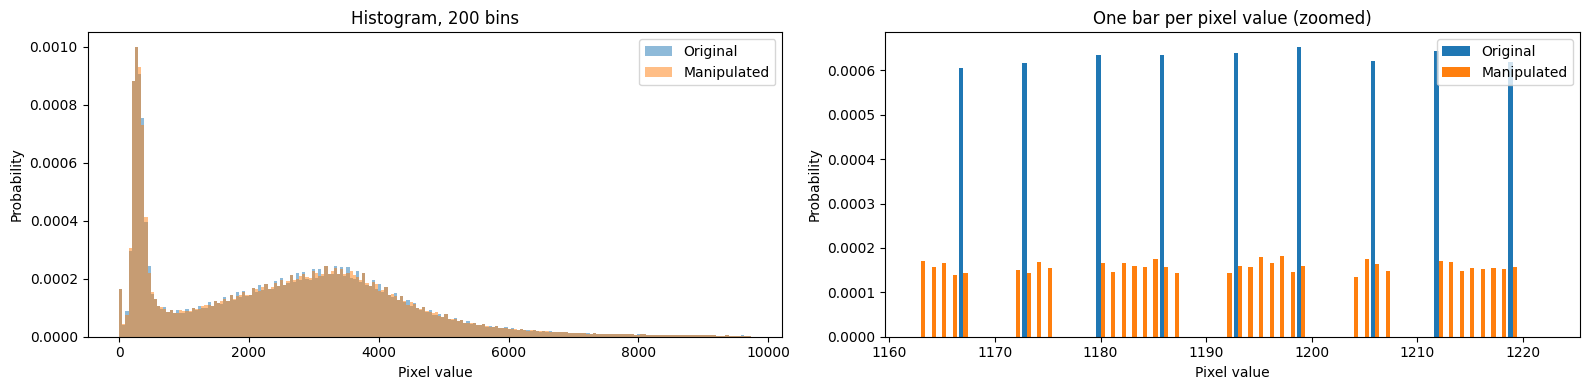

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# "normal" histogram with 200 bins
edges = np.linspace(*np.percentile(original, [0.5, 99.5]), 201)
axes[0].hist(original.ravel(), bins=edges, density=True, alpha=0.5, label="Original")
axes[0].hist(manipulated.ravel(), bins=edges, density=True, alpha=0.5, label="Manipulated")
axes[0].set_title("Histogram, 200 bins")

# one bar per integer value, in a narrow window
center = int(np.percentile(original, 30))# a point on the slope of the histogram
x = np.arange(center - 30, center + 30)
p_orig = np.bincount(original.ravel(), minlength=65536)[x] / original.size
p_manip = np.bincount(manipulated.ravel(), minlength=65536)[x] / manipulated.size
axes[1].bar(x - 0.2, p_orig, width=0.4, label="Original")
axes[1].bar(x + 0.2, p_manip, width=0.4, label="Manipulated")
axes[1].set_title("One bar per pixel value (zoomed)")

for a in axes:
    a.set_xlabel("Pixel value")
    a.set_ylabel("Probability")
    a.legend()
plt.tight_layout()
plt.show()

The histogram with 200 bins shows no difference between the original and the manipulated image, since a change of at most |3| is hidden within a single bin. The (zoomed in) histogram with one bar per pixel value reveals a clear difference. The original image only uses values spaced about 6,5 apart, as a result of rescaling. After manipulation, each of these values is spread over four neighboring values within its group (e.g. 1164–1167), each with about a quarter of the original frequency. Values that should not exist in a correctly rescaled image appear, which is a clear trace of manipulation.

In [45]:
for name, img in [("Original", original), ("Manipulated", manipulated)]:
    print(name, "– share of LSB values 0/1/2/3:",
          np.round(np.bincount((img & mask).ravel(), minlength=4) / img.size, 3))

Original – share of LSB values 0/1/2/3: [0.257 0.247 0.248 0.249]
Manipulated – share of LSB values 0/1/2/3: [0.25  0.249 0.25  0.25 ]


The two least significant bits of the original image are already almost uniformly distributed (25.7%, 24.7%, 24.8% and 24.9% for the values 0–3), so they behave like random noise. After manipulation, all four values occur with a frequency of exactly 25%. Looking at the least significant bits alone is therefore not enough to detect the manipulation.

## Observations from the Steganography part

* Replacing the two least significant bits of each pixel with random values does not affect the visual quality of the satellite image. The pixel values changed by at most |3|, which is less than 0.01% of the data range, the difference is invisible even in the zoomed fragment, and the PSNR reaches 88,2 dB. For 16-bit satellite data, such a change is even less noticeable than in typical 8-bit images, where the same modification corresponds to about 1% of the range.

* The answer to whether the manipulation can be seen in the probability density function depends on how the histogram is plotted. A standard histogram with wide bins does not show any difference, since the change of a few units is hidden within a single bin. Only a histogram with one bar per pixel value reveals it. In this case, the detection was particularly easy because of the way the data were prepared: the rescaling performed by the Copernicus Browser causes the original image to use only values on a regular grid spaced about 6.5 apart. The manipulation spreads each of these values over four neighboring ones, creating values that should not exist in the original data. In contrast, the least significant bits themselves do not reveal the manipulation, as they are almost uniformly distributed even in the original image.

* The histogram can therefore be used to detect manipulation of a satellite image, but with important limitations. It requires analysing the histogram at the level of individual values and knowing what the histogram of unmodified data should look like, for example that the values should form a regular grid. Without such knowledge or the original image for comparison, detection becomes much harder, especially since satellite data naturally contain measurement noise, which makes the least significant bits appear random anyway. If the data used all possible values instead of a regular grid, the manipulation would only cause a subtle staircase pattern in the histogram rather than filling clearly empty values.